<div style="font-family: 'Segoe UI', sans-serif; box-sizing: border-box;">
  <div style="background: #0f1923; border-radius: 14px; padding: 40px 50px; color: #e8edf2; position: relative; overflow: hidden;">
    <div style="position: absolute; top: 0; right: 0; width: 320px; height: 100%; opacity: 0.07; pointer-events: none;">
    </div>
    <div style="display: inline-block; width: fit-content; background: rgba(29,158,117,0.18); border: 1px solid rgba(93,202,165,0.35); border-radius: 6px; padding: 3px 12px; margin-bottom: 18px;">
      <span style="font-size: 11px; letter-spacing: 2px; text-transform: uppercase; color: #5DCAA5; font-weight: 500;">Tutorial</span>
    </div>
    <h1 style="margin: 0 0 6px 0; font-size: 2.5em; font-weight: 700; letter-spacing: -0.5px; color: #e8edf2; line-height: 1.15;">
      Getting Started with <span style="color: #5DCAA5;">Detecting Gravitational Waves</span>
    </h1>
    <p style="margin: 0 0 4px 0; font-size: 1.05em; color: rgba(232,237,242,0.55); font-weight: 300; letter-spacing: 0.5px;">
      This notebook serves as a mini captone project for the PDRP Fall 2025 program. Here, we will analyze real LIGO data to detect gravitational waves from black hole mergers - the same data that won the 2017 Nobel Prize.
    </p>
    </p>
    <div style="border-top: 1px solid rgba(93,202,165,0.2); margin: 22px 0 18px;"></div>
    <div style="display: flex; justify-content: space-between; align-items: flex-end; flex-wrap: wrap; gap: 12px;">
      <div style="display: flex; gap: 28px; flex-wrap: wrap;">
        <div>
          <p style="margin: 0 0 2px; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Authors</p>
          <p style="margin: 0; font-size: 0.95em; color: rgba(232,237,242,0.85);">Katie Gray</p>
        </div>
        <div>
          <p style="margin: 0 0 2px; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Description</p>
          <p style="margin: 0; font-size: 0.95em; color: rgba(232,237,242,0.85);">We will be using the PyCBC library, which is used to study gravitational-wave data, find astrophysical sources due to compact binary mergers, and study their parameters.</p>
        </div>
        <div>
          <p style="margin: 0 0 2px; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Docs & Install</p>
          <a href="https://pycbc.org/" style="margin: 0; font-size: 0.95em; color: #5DCAA5; text-decoration: none;">https://pycbc.org/ ↗</a>
        </div>
      </div>
      <div>
        <p style="margin: 0; font-size: 0.9em; color: rgba(232,237,242,0.4); font-weight: 300;">November 12, 2025</p>
      </div>
    </div>
  </div>
  <div style="margin-top: 14px; background: #0f1923; border-radius: 10px; padding: 18px 28px; display: flex; gap: 32px; flex-wrap: wrap;">
    <div style="display: flex; align-items: center; gap: 10px;">
      <div style="width: 8px; height: 8px; border-radius: 50%; background: #5DCAA5;"></div>
      <span style="font-size: 13px; color: rgba(232,237,242,0.6);">Apply signal processing to real detector data</span>
    </div>
    <div style="display: flex; align-items: center; gap: 10px;">
      <div style="width: 8px; height: 8px; border-radius: 50%; background: #1D9E75;"></div>
      <span style="font-size: 13px; color: rgba(232,237,242,0.6);">Understand noise in gravitational wave detectors</span>
    </div>
    <div style="display: flex; align-items: center; gap: 10px;">
      <div style="width: 8px; height: 8px; border-radius: 50%; background: #0F6E56;"></div>
      <span style="font-size: 13px; color: rgba(232,237,242,0.6);">Identify gravitational wave signals</span>
    </div>
  </div>
</div>

In [6]:
# Uncomment to install

#import sys
#!{sys.executable} -m pip install pycbc 

import warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
import numpy as np

<div style="font-family: 'Segoe UI', sans-serif; box-sizing: border-box; max-width: 100%; overflow: hidden;">
  <div style="background: #0f1923; border-radius: 14px; padding: 32px 42px; color: #e8edf2; box-sizing: border-box; max-width: 100%;">
    <!-- Section badge -->
    <div style="display: inline-block; width: fit-content; background: rgba(29,158,117,0.18); border: 1px solid rgba(93,202,165,0.35); border-radius: 6px; padding: 3px 12px; margin-bottom: 18px;">
      <span style="font-size: 11px; letter-spacing: 2px; text-transform: uppercase; color: #5DCAA5; font-weight: 500;">Part 1 — Raw Data</span>
    </div>
    <!-- Title -->
    <h2 style="margin: 0 0 8px 0; font-size: 1.8em; font-weight: 700; color: #e8edf2; line-height: 1.2;">
      Raw LIGO Data
    </h2>
    <p style="margin: 0 0 20px 0; font-size: 1.0em; color: rgba(232,237,242,0.5); font-weight: 300;">
      Event <span style="color: #5DCAA5;">GW150914</span> · 14 September 2015
    </p>
    <div style="border-top: 1px solid rgba(93,202,165,0.15); margin-bottom: 20px;"></div>
    <!-- Body text -->
    <p style="margin: 0 0 14px 0; font-size: 0.95em; color: rgba(232,237,242,0.8); line-height: 1.7;">
      The first direct observation of gravitational waves was made on 14 September 2015. Previously, gravitational waves had been inferred only indirectly, via their effect on the timing of pulsars in binary star systems. The waveform, detected by both LIGO observatories, matched the predictions of general relativity for a gravitational wave emanating from the inward spiral and merger of two black holes of
      <strong style="color: #5DCAA5;">36 M☉ and 29 M☉</strong>, and the subsequent ringdown of a single <strong style="color: #5DCAA5;">62 M☉</strong> black hole remnant.
    </p>
    <p style="margin: 0 0 20px 0; font-size: 0.95em; color: rgba(232,237,242,0.8); line-height: 1.7;">
      Below we will view the raw LIGO data — specifically 32 seconds of data around GW150914. Notice the significant low-frequency content (indicated by the large oscillations) and a DC offset present in the raw strain.
    </p>
    <!-- Info cards -->
    <div style="display: flex; gap: 12px; flex-wrap: wrap; margin-bottom: 20px;">
      <div style="flex: 1; min-width: 160px; background: rgba(93,202,165,0.07); border: 1px solid rgba(93,202,165,0.2); border-radius: 8px; padding: 14px 18px;">
        <p style="margin: 0 0 4px; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Source</p>
        <p style="margin: 0; font-size: 0.88em; color: rgba(232,237,242,0.8); line-height: 1.6;">
          Binary black hole merger<br>
          <code style="background: rgba(93,202,165,0.12); color: #5DCAA5; padding: 1px 5px; border-radius: 3px; font-size: 11px;">d_L ≈ 410 Mpc</code>
        </p>
      </div>
      <div style="flex: 1; min-width: 160px; background: rgba(93,202,165,0.07); border: 1px solid rgba(93,202,165,0.2); border-radius: 8px; padding: 14px 18px;">
        <p style="margin: 0 0 4px; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Detectors</p>
        <p style="margin: 0; font-size: 0.88em; color: rgba(232,237,242,0.8); line-height: 1.6;">
          H1 (Hanford, WA) · L1 (Livingston, LA)<br>
          <code style="background: rgba(93,202,165,0.12); color: #5DCAA5; padding: 1px 5px; border-radius: 3px; font-size: 11px;">Δt ≈ 7 ms</code>
        </p>
      </div>
      <div style="flex: 1; min-width: 160px; background: rgba(93,202,165,0.07); border: 1px solid rgba(93,202,165,0.2); border-radius: 8px; padding: 14px 18px;">
        <p style="margin: 0 0 4px; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Data window</p>
        <p style="margin: 0; font-size: 0.88em; color: rgba(232,237,242,0.8); line-height: 1.6;">
          32 s around merger · GPS time<br>
          <code style="background: rgba(93,202,165,0.12); color: #5DCAA5; padding: 1px 5px; border-radius: 3px; font-size: 11px;">t₀ = 1126259462.4</code>
        </p>
      </div>
    </div>
    <!-- Questions box -->
    <div style="background: rgba(93,202,165,0.07); border: 1px solid rgba(93,202,165,0.2); border-radius: 8px; padding: 18px 22px; margin-bottom: 16px;">
      <p style="margin: 0 0 12px 0; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Guided Short Answer</p>
      <ol style="margin: 0; padding-left: 20px; font-size: 0.9em; color: rgba(232,237,242,0.8); line-height: 2.0;">
        <li>What causes noise in gravitational wave detectors?</li>
        <li>Will noise be uniform across frequencies? Why or why not?</li>
        <li>What will a gravitational wave signal look like?</li>
        <li>How do we plot that signal? Describe GPS time. What is meant by H1 &amp; L1?</li>
      </ol>
    </div>
    <!-- Note / link -->
    <div style="background: rgba(255,255,255,0.04); border-left: 3px solid rgba(93,202,165,0.5); border-radius: 0 6px 6px 0; padding: 12px 16px;">
      <p style="margin: 0; font-size: 0.85em; color: rgba(232,237,242,0.55); line-height: 1.6;">
        <span style="color: #5DCAA5; font-weight: 600;">Note —</span>
        Original tutorial:
        <a href="https://colab.research.google.com/github/gwastro/pycbc-tutorials/blob/master/tutorial/2_VisualizationSignalProcessing.ipynb#scrollTo=F5lrbntVb3GW"
           style="color: #5DCAA5; text-decoration: none; border-bottom: 1px solid rgba(93,202,165,0.35);">
          PyCBC Tutorial: Visualization of Data and Signal Processing ↗
        </a>
      </p>
    </div>
  </div>
</div>


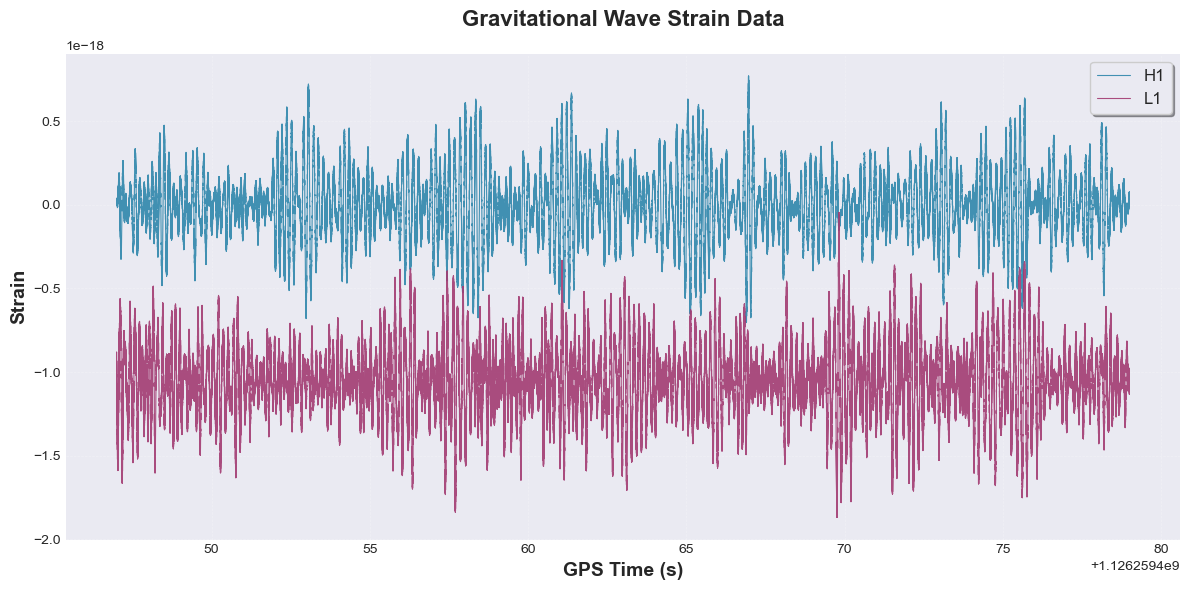

In [7]:
%matplotlib inline

# Read in the data around GW150914
from pycbc.catalog import Merger
import pylab

m = Merger('GW150914')

#we will plot the strain vs the gps time!

# read in data 
data = {}
for ifo in ['H1', 'L1']:
    data[ifo] = m.strain(ifo)

# make a fancy plot 
plt.figure(figsize=(12, 6))
plt.style.use('seaborn-v0_8-darkgrid') 
colors = {'H1': '#2E86AB', 'L1': '#A23B72'}  # Blue and magenta

# plot
for ifo in data:
    plt.plot(data[ifo].sample_times, data[ifo], 
             label=ifo, 
             color=colors[ifo],
             linewidth=0.8,
             alpha=0.9)

# title & labels 
plt.ylabel('Strain', fontsize=14, fontweight='bold')
plt.xlabel('GPS Time (s)', fontsize=14, fontweight='bold')
plt.title('Gravitational Wave Strain Data', fontsize=16, fontweight='bold', pad=20)

# legend
plt.legend(frameon=True, 
          shadow=True, 
          fontsize=12,
          loc='upper right',
          fancybox=True)

# axes formatting 
plt.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
plt.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.show()

<div style="font-family: 'Segoe UI', sans-serif; box-sizing: border-box; max-width: 100%; overflow: hidden;">
  <div style="background: #0f1923; border-radius: 14px; padding: 28px 42px; color: #e8edf2; box-sizing: border-box; max-width: 100%;">
    <!-- Questions box -->
    <div style="background: rgba(93,202,165,0.07); border: 1px solid rgba(93,202,165,0.2); border-radius: 8px; padding: 18px 22px; margin-bottom: 16px;">
      <p style="margin: 0 0 12px 0; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Guided Short Answer</p>
      <ol start="5" style="margin: 0; padding-left: 20px; font-size: 0.9em; color: rgba(232,237,242,0.8); line-height: 2.0;">
        <li>What dominates the signal? Can you see a gravitational wave?</li>
        <li>At what frequencies is the detector most sensitive?</li>
        <li>Why so much low-frequency noise? What are these noise sources?</li>
      </ol>
    </div>
    <!-- Think prompt -->
    <div style="background: rgba(255,255,255,0.04); border-left: 3px solid rgba(93,202,165,0.5); border-radius: 0 6px 6px 0; padding: 12px 16px;">
      <p style="margin: 0; font-size: 0.85em; color: rgba(232,237,242,0.55); line-height: 1.6;">
        <span style="color: #5DCAA5; font-weight: 600;">Think —</span>
        Can you identify a signal by eye, or does this look random? Zoom in on one second of data and see. <span style="color: rgba(232,237,242,0.35);">(done in the next code block)</span>
      </p>
    </div>

  </div>
</div>

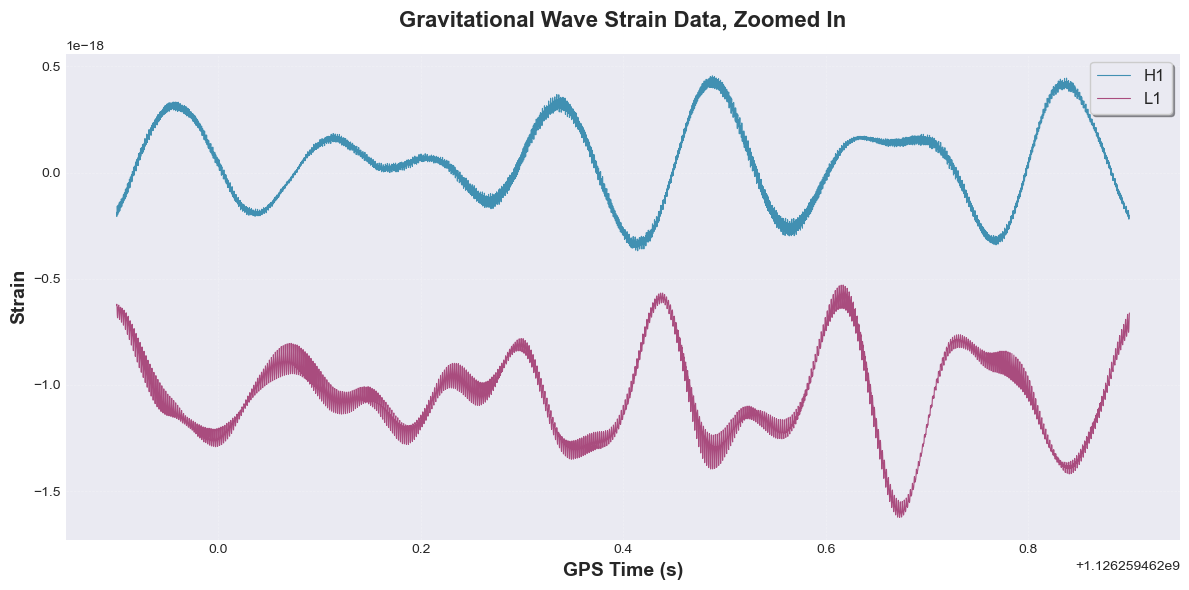

In [8]:
# Zoom in to one second of data 

plt.figure(figsize=(12, 6))
plt.style.use('seaborn-v0_8-darkgrid') 
colors = {'H1': '#2E86AB', 'L1': '#A23B72'}  # Blue and magenta

# plot
for ifo in data:
    # can try different time slices 
    zoom = data[ifo].time_slice(m.time - 0.5, m.time + 0.5)
    plt.plot(zoom.sample_times, zoom, 
             label=ifo, 
             color=colors[ifo],
             linewidth=0.8,
             alpha=0.9)

# title & labels 
plt.ylabel('Strain', fontsize=14, fontweight='bold')
plt.xlabel('GPS Time (s)', fontsize=14, fontweight='bold')
plt.title('Gravitational Wave Strain Data, Zoomed In', fontsize=16, fontweight='bold', pad=20)

# legend
plt.legend(frameon=True, 
          shadow=True, 
          fontsize=12,
          loc='upper right',
          fancybox=True)

# axes formatting 
plt.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
plt.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.show()

<div style="font-family: 'Segoe UI', sans-serif; box-sizing: border-box; max-width: 100%; overflow: hidden;">
  <div style="background: #0f1923; border-radius: 14px; padding: 32px 42px; color: #e8edf2; box-sizing: border-box; max-width: 100%;">
    <!-- Section badge -->
    <div style="display: inline-block; width: fit-content; background: rgba(29,158,117,0.18); border: 1px solid rgba(93,202,165,0.35); border-radius: 6px; padding: 3px 12px; margin-bottom: 18px;">
      <span style="font-size: 11px; letter-spacing: 2px; text-transform: uppercase; color: #5DCAA5; font-weight: 500;">Part 2 — Signal Processing</span>
    </div>
    <!-- Title -->
    <h2 style="margin: 0 0 8px 0; font-size: 1.8em; font-weight: 700; color: #e8edf2; line-height: 1.2;">
      Highpass Filtering
    </h2>
    <p style="margin: 0 0 20px 0; font-size: 1.0em; color: rgba(232,237,242,0.5); font-weight: 300;">
      Suppressing low-frequency noise · <span style="color: #5DCAA5;">FIR filter</span> · cutoff 15 Hz
    </p>
    <div style="border-top: 1px solid rgba(93,202,165,0.15); margin-bottom: 20px;"></div>
    <!-- Body text -->
    <p style="margin: 0 0 14px 0; font-size: 0.95em; color: rgba(232,237,242,0.8); line-height: 1.7;">
      Binary black hole signals live in the <strong style="color: #5DCAA5;">~30–500 Hz</strong> range — but the raw strain data is swamped by low-frequency content from seismic and thermal noise. A highpass filter suppresses everything below the cutoff, bringing the dynamic range under control and making higher-frequency structure visible.
    </p>
    <p style="margin: 0 0 20px 0; font-size: 0.95em; color: rgba(232,237,242,0.8); line-height: 1.7;">
      Below we apply a finite-impulse-response (FIR) highpass at 15 Hz. Notice how the large low-frequency oscillations are suppressed — though some dominant frequencies clearly remain.
    </p>
    <!-- Question prompt -->
    <div style="background: rgba(255,255,255,0.04); border-left: 3px solid rgba(93,202,165,0.5); border-radius: 0 6px 6px 0; padding: 12px 16px;">
      <p style="margin: 0; font-size: 0.85em; color: rgba(232,237,242,0.55); line-height: 1.6;">
        <span style="color: #5DCAA5; font-weight: 600;">Question —</span>
        What is a highpass filter? Try varying the cutoff frequency — does changing it affect what you see?
      </p>
    </div>
  </div>
</div>

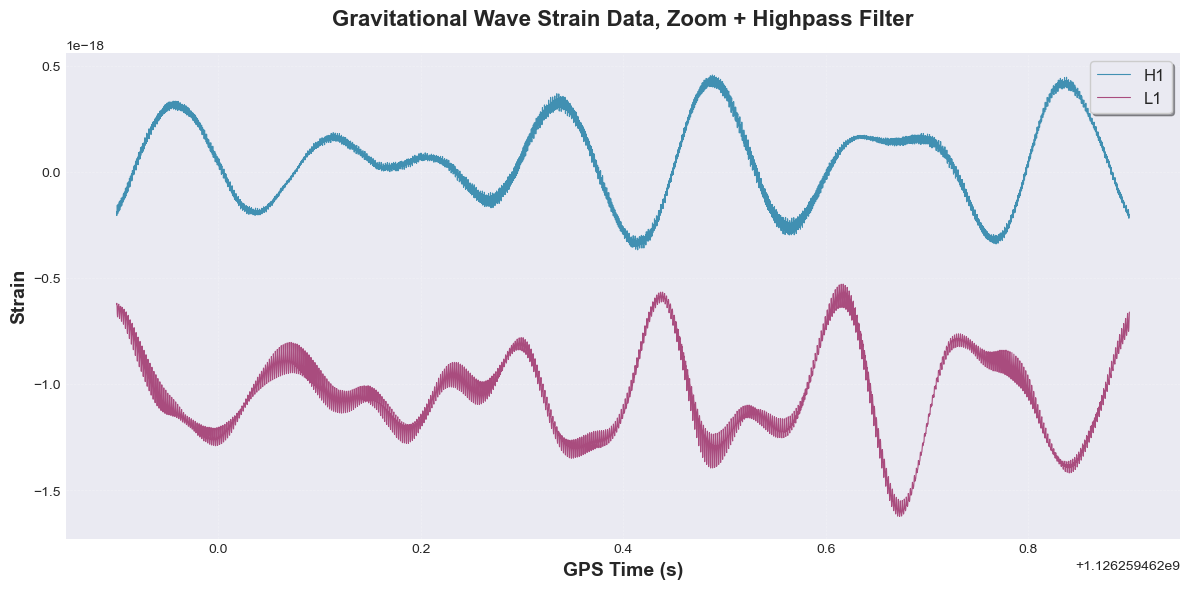

In [9]:
# Implement Filter 

plt.figure(figsize=(12, 6))
plt.style.use('seaborn-v0_8-darkgrid') 
colors = {'H1': '#2E86AB', 'L1': '#A23B72'}  # Blue and magenta

# plot
for ifo in data:
    # Apply a highpass filter to the data. This suppresses the low
    # frequency content of the data. We choose here a finite-impulse-response (FIR).
    # Options
    # 1) highpass frequency
    # 2) half sample length of highpass filter 
    #(higher value will give less ripple in passband)
    high_data = data[ifo].highpass_fir(15, 512) # Highpass point is 15 Hz, vary this 
    
    # The time slice method can give just a portion of the time
    # series using GPS start and stop times
    zoom = data[ifo].time_slice(m.time - 0.5, m.time + 0.5)
    plt.plot(zoom.sample_times, zoom, 
             label=ifo, 
             color=colors[ifo],
             linewidth=0.8,
             alpha=0.9)

# title & labels 
plt.ylabel('Strain', fontsize=14, fontweight='bold')
plt.xlabel('GPS Time (s)', fontsize=14, fontweight='bold')
plt.title('Gravitational Wave Strain Data, Zoom + Highpass Filter', fontsize=16, fontweight='bold', pad=20)

# legend
plt.legend(frameon=True, 
          shadow=True, 
          fontsize=12,
          loc='upper right',
          fancybox=True)

# axes formatting 
plt.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
plt.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.show()


<div style="font-family: 'Segoe UI', sans-serif; box-sizing: border-box; max-width: 100%; overflow: hidden;">
  <div style="background: #0f1923; border-radius: 14px; padding: 32px 42px; color: #e8edf2; box-sizing: border-box; max-width: 100%;">
    <!-- Section badge -->
    <div style="display: inline-block; width: fit-content; background: rgba(29,158,117,0.18); border: 1px solid rgba(93,202,165,0.35); border-radius: 6px; padding: 3px 12px; margin-bottom: 18px;">
      <span style="font-size: 11px; letter-spacing: 2px; text-transform: uppercase; color: #5DCAA5; font-weight: 500;">Part 3 — Frequency Domain</span>
    </div>
    <!-- Title -->
    <h2 style="margin: 0 0 8px 0; font-size: 1.8em; font-weight: 700; color: #e8edf2; line-height: 1.2;">
      Power Spectral Density
    </h2>
    <p style="margin: 0 0 20px 0; font-size: 1.0em; color: rgba(232,237,242,0.5); font-weight: 300;">
      Noise characterisation · <span style="color: #5DCAA5;">Welch's method</span> · 4 s segments
    </p>
    <div style="border-top: 1px solid rgba(93,202,165,0.15); margin-bottom: 20px;"></div>
    <!-- Body -->
    <p style="margin: 0 0 14px 0; font-size: 0.95em; color: rgba(232,237,242,0.8); line-height: 1.7;">
      Understanding how noise power varies with frequency is fundamental to LIGO data analysis. Rather than a single noise floor, the detector has a frequency-dependent noise structure — and knowing its shape is what allows us to find a signal buried inside it.
    </p>
    <p style="margin: 0 0 20px 0; font-size: 0.95em; color: rgba(232,237,242,0.8); line-height: 1.7;">
      Here we estimate the PSD using <strong style="color: #5DCAA5;">Welch's method</strong>, which sub-divides the data into overlapping 4 s segments, computes the periodogram of each, and averages them, trading frequency resolution for a stabler estimate. Several features stand out in the result: orders-of-magnitude excess power at low frequencies from seismic and thermal noise; sharp lines at <strong style="color: #5DCAA5;">60 Hz</strong> and harmonics from mains power; narrow peaks from the <strong style="color: #5DCAA5;">violin modes</strong> of the mirror suspension fibres.
    </p>
    <!-- Noise source cards -->
    <div style="display: flex; gap: 12px; flex-wrap: wrap; margin-bottom: 20px;">
      <div style="flex: 1; min-width: 140px; background: rgba(93,202,165,0.07); border: 1px solid rgba(93,202,165,0.2); border-radius: 8px; padding: 14px 18px;">
        <p style="margin: 0 0 4px; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Low freq (&lt; 30 Hz)</p>
        <p style="margin: 0; font-size: 0.88em; color: rgba(232,237,242,0.8); line-height: 1.6;">Seismic &amp; gravity gradient noise; suspension thermal noise</p>
      </div>
      <div style="flex: 1; min-width: 140px; background: rgba(93,202,165,0.07); border: 1px solid rgba(93,202,165,0.2); border-radius: 8px; padding: 14px 18px;">
        <p style="margin: 0 0 4px; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Mid band (lines)</p>
        <p style="margin: 0; font-size: 0.88em; color: rgba(232,237,242,0.8); line-height: 1.6;">60 Hz mains &amp; harmonics; mirror violin modes ~500 Hz</p>
      </div>
      <div style="flex: 1; min-width: 140px; background: rgba(93,202,165,0.07); border: 1px solid rgba(93,202,165,0.2); border-radius: 8px; padding: 14px 18px;">
        <p style="margin: 0 0 4px; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">High freq (&gt; 1 kHz)</p>
        <p style="margin: 0; font-size: 0.88em; color: rgba(232,237,242,0.8); line-height: 1.6;">Shot noise (photon counting statistics); roll-off from anti-aliasing filter</p>
      </div>
    </div>
    <!-- Questions -->
    <div style="background: rgba(93,202,165,0.07); border: 1px solid rgba(93,202,165,0.2); border-radius: 8px; padding: 18px 22px;">
      <p style="margin: 0 0 12px 0; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Guided Short Answer</p>
      <ol start="8" style="margin: 0; padding-left: 20px; font-size: 0.9em; color: rgba(232,237,242,0.8); line-height: 2.0;">
        <li>In signal processing, what is the power spectrum? What are its units for strain data?</li>
        <li>What is Welch's method, and why does averaging segments reduce variance in the estimate?</li>
        <li>Can you identify the 60 Hz line and its harmonics in the plot? What about the violin modes?</li>
        <li>The sensitivity curve has a broad minimum around 100–300 Hz — why is this the "sweet spot" for GW detection?</li>
      </ol>
    </div>
  </div>
</div>

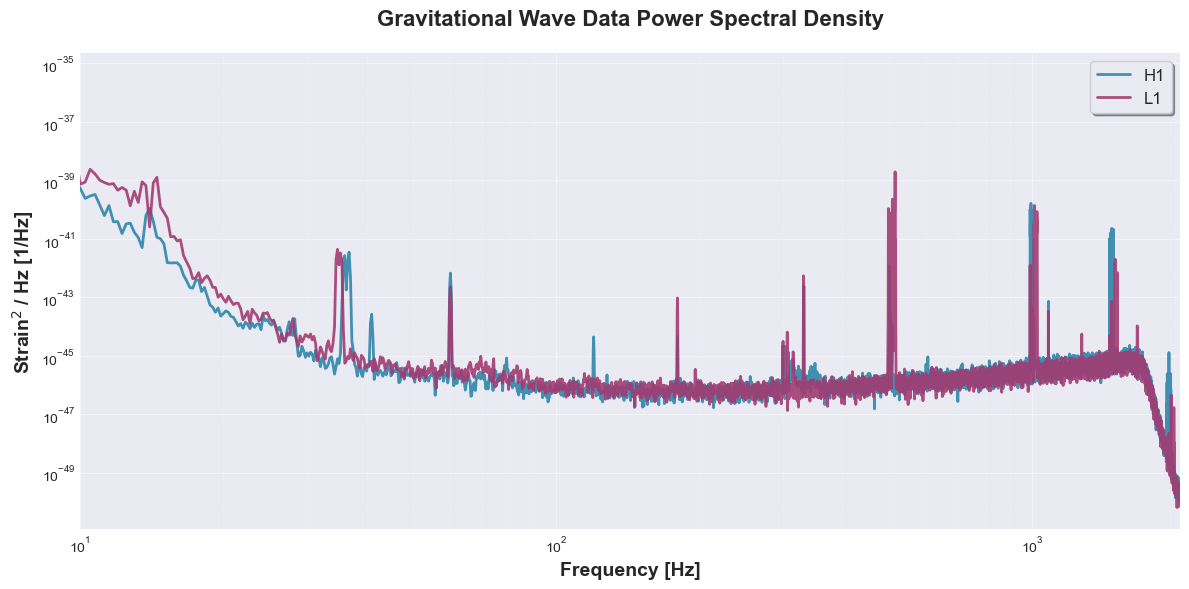

In [10]:
# PSD

plt.figure(figsize=(12, 6))
plt.style.use('seaborn-v0_8-darkgrid') 
colors = {'H1': '#2E86AB', 'L1': '#A23B72'}  # Blue and magenta

# plot
for ifo in data:
    # This estimates the PSD by sub-dividing the data into overlapping
    # 4s long segments. (See Welch's method)
    psd = data[ifo].psd(4)
    
    # Note that the psd is a FrequencySeries!
    plt.loglog(psd.sample_frequencies, psd, 
               label=ifo,
               color=colors[ifo],
               linewidth=2,
               alpha=0.9)
    

# labels 
plt.ylabel(r'Strain$^2$ / Hz [1/Hz]', fontsize=14, fontweight='bold')
plt.xlabel('Frequency [Hz]', fontsize=14, fontweight='bold')
plt.title('Gravitational Wave Data Power Spectral Density', 
          fontsize=16, fontweight='bold', pad=20)

# legend
plt.legend(frameon=True, 
          shadow=True, 
          fontsize=12,
          loc='upper right',
          fancybox=True)

# grid
plt.grid(True, which='both', alpha=0.3, linestyle='--', linewidth=0.5)
plt.grid(True, which='major', alpha=0.5, linestyle='-', linewidth=0.8)

# axis limits
plt.xlim(10, 2048)
plt.minorticks_on()

# show
plt.tight_layout()
plt.show()

<div style="font-family: 'Segoe UI', sans-serif; box-sizing: border-box; max-width: 100%; overflow: hidden;">
  <div style="background: #0f1923; border-radius: 14px; padding: 32px 42px; color: #e8edf2; box-sizing: border-box; max-width: 100%;">
    <!-- Section badge -->
    <div style="display: inline-block; width: fit-content; background: rgba(29,158,117,0.18); border: 1px solid rgba(93,202,165,0.35); border-radius: 6px; padding: 3px 12px; margin-bottom: 18px;">
      <span style="font-size: 11px; letter-spacing: 2px; text-transform: uppercase; color: #5DCAA5; font-weight: 500;">Part 4 — Noise Normalisation</span>
    </div>
    <!-- Title -->
    <h2 style="margin: 0 0 8px 0; font-size: 1.8em; font-weight: 700; color: #e8edf2; line-height: 1.2;">
      Whitening
    </h2>
    <p style="margin: 0 0 20px 0; font-size: 1.0em; color: rgba(232,237,242,0.5); font-weight: 300;">
      Flattening the noise floor · <span style="color: #5DCAA5;">PSD-based normalisation</span>
    </p>
    <div style="border-top: 1px solid rgba(93,202,165,0.15); margin-bottom: 20px;"></div>
    <!-- Body -->
    <p style="margin: 0 0 14px 0; font-size: 0.95em; color: rgba(232,237,242,0.8); line-height: 1.7;">
      Whitening divides the data by the square root of the estimated PSD in the frequency domain, then transforms back to the time domain. The effect is to normalise the noise so it has <strong style="color: #5DCAA5;">equal power at every frequency</strong>, which is a flat, white spectrum. In the raw data, low-frequency noise is so much louder than the signal band that it completely dominates; whitening removes that imbalance.
    </p>
    <p style="margin: 0 0 20px 0; font-size: 0.95em; color: rgba(232,237,242,0.8); line-height: 1.7;">
      After whitening, any excess power above the noise floor (such as a gravitational wave!) appears as a clear deviation from zero. This is why whitening is a standard first step before by-eye inspection: it places every frequency on equal footing so nothing is artificially hidden by a louder neighbour.
    </p>
    <!-- Before / after conceptual cards -->
    <div style="display: flex; gap: 12px; flex-wrap: wrap; margin-bottom: 20px;">
      <div style="flex: 1; min-width: 160px; background: rgba(93,202,165,0.07); border: 1px solid rgba(93,202,165,0.2); border-radius: 8px; padding: 14px 18px;">
        <p style="margin: 0 0 4px; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Before whitening</p>
        <p style="margin: 0; font-size: 0.88em; color: rgba(232,237,242,0.8); line-height: 1.6;">PSD steeply coloured; low frequencies dominate by orders of magnitude; signal invisible</p>
      </div>
      <div style="flex: 1; min-width: 160px; background: rgba(93,202,165,0.07); border: 1px solid rgba(93,202,165,0.2); border-radius: 8px; padding: 14px 18px;">
        <p style="margin: 0 0 4px; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">After whitening</p>
        <p style="margin: 0; font-size: 0.88em; color: rgba(232,237,242,0.8); line-height: 1.6;">Flat noise floor; signal-band excess visible as coherent structure above noise</p>
      </div>
      <div style="flex: 1; min-width: 160px; background: rgba(93,202,165,0.07); border: 1px solid rgba(93,202,165,0.2); border-radius: 8px; padding: 14px 18px;">
        <p style="margin: 0 0 4px; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Mathematically</p>
        <p style="margin: 0; font-size: 0.88em; color: rgba(232,237,242,0.8); line-height: 1.6;">
          <code style="background: rgba(93,202,165,0.12); color: #5DCAA5; padding: 1px 5px; border-radius: 3px; font-size: 11px;">h̃_w(f) = h̃(f) / √S_n(f)</code>
        </p>
      </div>
    </div>
    <!-- Questions -->
    <div style="background: rgba(93,202,165,0.07); border: 1px solid rgba(93,202,165,0.2); border-radius: 8px; padding: 18px 22px;">
      <p style="margin: 0 0 12px 0; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Guided Short Answer</p>
      <ol start="10" style="margin: 0; padding-left: 20px; font-size: 0.9em; color: rgba(232,237,242,0.8); line-height: 2.0;">
        <li>Can you see something signal-like in the whitened data? Describe its shape.</li>
        <li>Why does whitening reveal the signal when the raw data showed nothing?</li>
        <li>Whitening uses the PSD estimated from the same data segment. What could go wrong if the PSD estimate is poor?</li>
        <li>After whitening, what should the noise look like statistically? What distribution would you expect?</li>
      </ol>
    </div>
  </div>
</div>

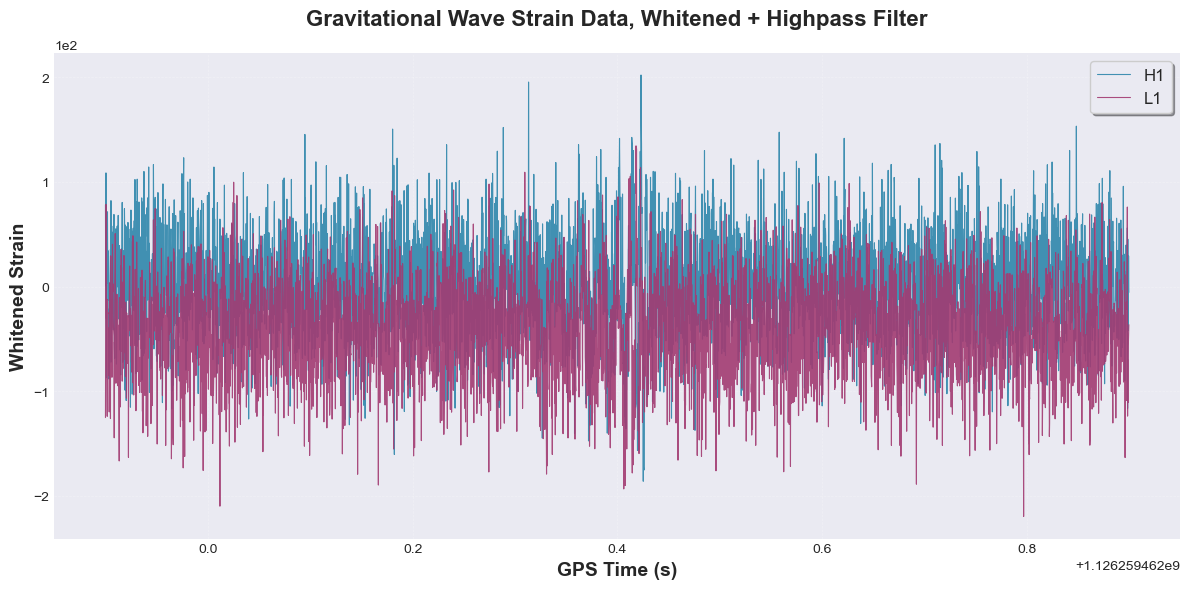

In [11]:
# Whiten the data

whitened = {}

plt.figure(figsize=(12, 6))
plt.style.use('seaborn-v0_8-darkgrid') 
colors = {'H1': '#2E86AB', 'L1': '#A23B72'}  # Blue and magenta

# plot
for ifo in data:
    # This produces a whitened set.
    # This works by estimating the power spectral density from the
    # data and then flattening the frequency response.
    # (1) The first option sets the duration in seconds of each
    #     sample of the data used as part of the PSD estimate.
    # (2) The second option sets the duration of the filter to apply
    
    whitened[ifo] = data[ifo].whiten(4, 4)
    zoom = whitened[ifo].time_slice(m.time - 0.5, m.time + 0.5) 
    plt.plot(zoom.sample_times, zoom, 
             label=ifo, 
             color=colors[ifo],
             linewidth=0.8,
             alpha=0.9)

# title & labels 
plt.ylabel('Whitened Strain', fontsize=14, fontweight='bold')
plt.xlabel('GPS Time (s)', fontsize=14, fontweight='bold')
plt.title('Gravitational Wave Strain Data, Whitened + Highpass Filter', fontsize=16, fontweight='bold', pad=20)

# legend
plt.legend(frameon=True, 
          shadow=True, 
          fontsize=12,
          loc='upper right',
          fancybox=True)

# axes formatting 
plt.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
plt.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.show()

<div style="font-family: 'Segoe UI', sans-serif; box-sizing: border-box; max-width: 100%; overflow: hidden;">
  <div style="background: #0f1923; border-radius: 14px; padding: 32px 42px; color: #e8edf2; box-sizing: border-box; max-width: 100%;">
    <!-- Section badge -->
    <div style="display: inline-block; width: fit-content; background: rgba(29,158,117,0.18); border: 1px solid rgba(93,202,165,0.35); border-radius: 6px; padding: 3px 12px; margin-bottom: 18px;">
      <span style="font-size: 11px; letter-spacing: 2px; text-transform: uppercase; color: #5DCAA5; font-weight: 500;">Part 5 — Signal Isolation</span>
    </div>
    <!-- Title -->
    <h2 style="margin: 0 0 8px 0; font-size: 1.8em; font-weight: 700; color: #e8edf2; line-height: 1.2;">
      Bandpass Filtering
    </h2>
    <p style="margin: 0 0 20px 0; font-size: 1.0em; color: rgba(232,237,242,0.5); font-weight: 300;">
      Isolating the signal band · <span style="color: #5DCAA5;">30 – 250 Hz</span> · FIR highpass + lowpass
    </p>
    <div style="border-top: 1px solid rgba(93,202,165,0.15); margin-bottom: 20px;"></div>
    <!-- Body -->
    <p style="margin: 0 0 14px 0; font-size: 0.95em; color: rgba(232,237,242,0.8); line-height: 1.7;">
      Even after whitening, the data still contains power outside the frequency range where GW150914 actually lives. A bandpass between <strong style="color: #5DCAA5;">30 and 250 Hz</strong> discards everything else — the residual low-frequency drift below 30 Hz and the shot-noise-dominated band above 250 Hz — leaving only the frequencies that carry the merger signal.
    </p>
    <p style="margin: 0 0 20px 0; font-size: 0.95em; color: rgba(232,237,242,0.8); line-height: 1.7;">
      This is implemented as a chain of two FIR filters: a highpass at 30 Hz (applied to the whitened data) followed by a lowpass at 250 Hz. After this step the chirp should be clearly visible by eye in both detectors.
    </p>
    <!-- Parameter cards -->
    <div style="display: flex; gap: 12px; flex-wrap: wrap;">
      <div style="flex: 1; min-width: 140px; background: rgba(93,202,165,0.07); border: 1px solid rgba(93,202,165,0.2); border-radius: 8px; padding: 14px 18px;">
        <p style="margin: 0 0 4px; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Lower cutoff</p>
        <p style="margin: 0; font-size: 0.88em; color: rgba(232,237,242,0.8); line-height: 1.6;">
          <code style="background: rgba(93,202,165,0.12); color: #5DCAA5; padding: 1px 5px; border-radius: 3px; font-size: 11px;">f_low = 30 Hz</code><br>
          removes residual seismic &amp; suspension noise
        </p>
      </div>
      <div style="flex: 1; min-width: 140px; background: rgba(93,202,165,0.07); border: 1px solid rgba(93,202,165,0.2); border-radius: 8px; padding: 14px 18px;">
        <p style="margin: 0 0 4px; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Upper cutoff</p>
        <p style="margin: 0; font-size: 0.88em; color: rgba(232,237,242,0.8); line-height: 1.6;">
          <code style="background: rgba(93,202,165,0.12); color: #5DCAA5; padding: 1px 5px; border-radius: 3px; font-size: 11px;">f_high = 250 Hz</code><br>
          removes shot-noise-dominated high-freq band
        </p>
      </div>
    </div>
  </div>
</div>

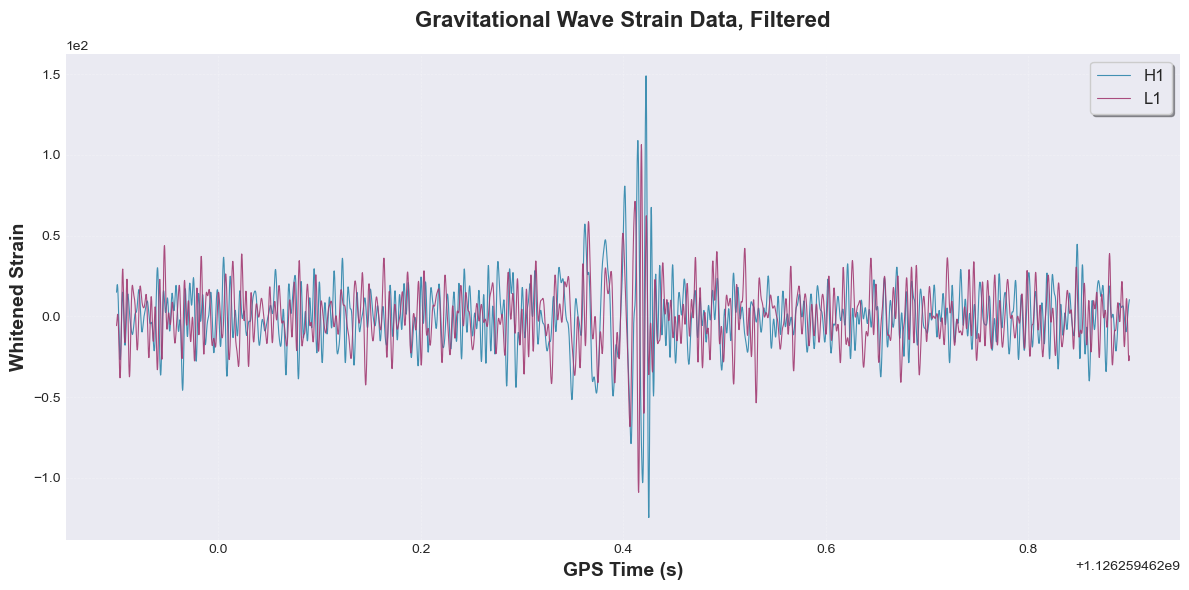

In [12]:
# Bandpasses 

plt.figure(figsize=(12, 6))
plt.style.use('seaborn-v0_8-darkgrid') 
colors = {'H1': '#2E86AB', 'L1': '#A23B72'}  # Blue and magenta

# plot
for ifo in data:
   # Apply a highpass filter (at 30 Hz) followed by an lowpass filter (at 250 Hz)
    bpsd = whitened[ifo].highpass_fir(30, 512).lowpass_fir(250, 512)

    zoom = bpsd.time_slice(m.time - 0.5, m.time + 0.5)
    
    plt.plot(zoom.sample_times, zoom, 
             label=ifo, 
             color=colors[ifo],
             linewidth=0.8,
             alpha=0.9)

# title & labels 
plt.ylabel('Whitened Strain', fontsize=14, fontweight='bold')
plt.xlabel('GPS Time (s)', fontsize=14, fontweight='bold')
plt.title('Gravitational Wave Strain Data, Filtered', fontsize=16, fontweight='bold', pad=20)

# legend
plt.legend(frameon=True, 
          shadow=True, 
          fontsize=12,
          loc='upper right',
          fancybox=True)

# axes formatting 
plt.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
plt.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.show()

<div style="font-family: 'Segoe UI', sans-serif; box-sizing: border-box; max-width: 100%; overflow: hidden;">
  <div style="background: #0f1923; border-radius: 14px; padding: 32px 42px; color: #e8edf2; box-sizing: border-box; max-width: 100%;">
    <!-- Section badge -->
    <div style="display: inline-block; width: fit-content; background: rgba(29,158,117,0.18); border: 1px solid rgba(93,202,165,0.35); border-radius: 6px; padding: 3px 12px; margin-bottom: 18px;">
      <span style="font-size: 11px; letter-spacing: 2px; text-transform: uppercase; color: #5DCAA5; font-weight: 500;">Part 6 — Detection</span>
    </div>
    <!-- Title -->
    <h2 style="margin: 0 0 8px 0; font-size: 1.8em; font-weight: 700; color: #e8edf2; line-height: 1.2;">
      Examining the Signal
    </h2>
    <p style="margin: 0 0 20px 0; font-size: 1.0em; color: rgba(232,237,242,0.5); font-weight: 300;">
      Coincidence detection · <span style="color: #5DCAA5;">H1 &amp; L1 alignment</span> · chirp morphology
    </p>
    <div style="border-top: 1px solid rgba(93,202,165,0.15); margin-bottom: 20px;"></div>
    <!-- Body -->
    <p style="margin: 0 0 14px 0; font-size: 0.95em; color: rgba(232,237,242,0.8); line-height: 1.7;">
      After bandpassing, an excess above the noise floor is visible near the merger time. To confirm this is a real astrophysical signal and not an instrumental artefact, we zoom in and <strong style="color: #5DCAA5;">align the two detectors</strong> in time. A genuine gravitational wave must appear in both H1 and L1 with a time delay consistent with the light travel time between the sites (~10 ms maximum) and with matching phase evolution.
    </p>
    <p style="margin: 0 0 20px 0; font-size: 0.95em; color: rgba(232,237,242,0.8); line-height: 1.7;">
      For GW150914, L1 is shifted forward by <strong style="color: #5DCAA5;">+7 ms</strong> and inverted (×−1) to account for the different orientations of the two interferometers relative to the source direction. After these corrections the waveforms from both sites should overlap, confirming the signal is real.
    </p>
    <!-- Questions -->
    <div style="background: rgba(93,202,165,0.07); border: 1px solid rgba(93,202,165,0.2); border-radius: 8px; padding: 18px 22px; margin-bottom: 16px;">
      <p style="margin: 0 0 12px 0; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Guided Short Answer</p>
      <ol start="12" style="margin: 0; padding-left: 20px; font-size: 0.9em; color: rgba(232,237,242,0.8); line-height: 2.0;">
        <li>Do the H1 and L1 signals match after alignment? What would it mean if they didn't?</li>
        <li>Does the frequency stay constant or change through the signal? Describe what you see.</li>
        <li>Why is the signal called a "chirp"? What is the physical process driving the frequency evolution?</li>
        <li>Count the visible wave cycles. What does the number of cycles tell you about the orbital separation at merger?</li>
        <li>The signal amplitude grows before merger then cuts off sharply. Why does it grow, and what causes the cutoff?</li>
        <li>Why is the 7 ms time delay scientifically useful beyond just alignment — what else can it constrain?</li>
      </ol>
    </div>
    <!-- Listen prompt -->
    <div style="background: rgba(255,255,255,0.04); border-left: 3px solid rgba(93,202,165,0.5); border-radius: 0 6px 6px 0; padding: 12px 16px;">
      <p style="margin: 0; font-size: 0.85em; color: rgba(232,237,242,0.55); line-height: 1.6;">
        <span style="color: #5DCAA5; font-weight: 600;">Listen —</span>
        You can actually hear the chirp as an audio file:
        <a href="https://www.youtube.com/watch?v=TWqhUANNFXw"
           style="color: #5DCAA5; text-decoration: none; border-bottom: 1px solid rgba(93,202,165,0.35);">
          GW150914 chirp · LIGO, September 14 2015 ↗
        </a>
      </p>
    </div>
  </div>
</div>


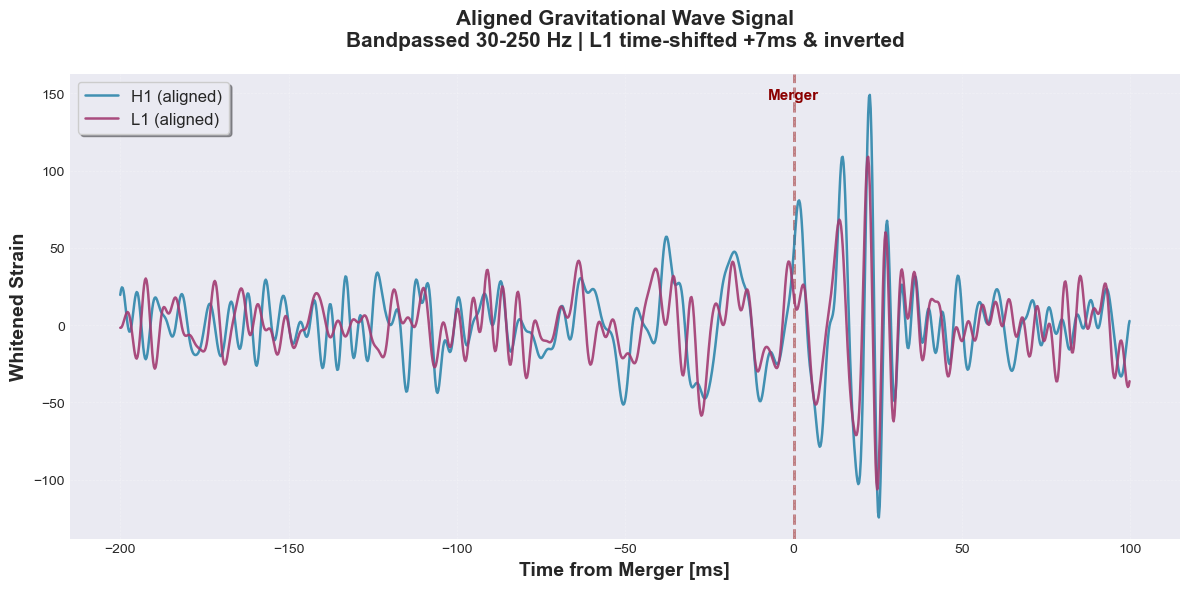

In [13]:
plt.figure(figsize=(12, 6))
plt.style.use('seaborn-v0_8-darkgrid') 
colors = {'H1': '#2E86AB', 'L1': '#A23B72'}  # Blue and magenta

for ifo in whitened:

    # Apply a highpass filter (at 30 Hz) followed by an lowpass filter (at 250 Hz)
    
    bpsd = whitened[ifo].highpass_fir(30, 512).lowpass_fir(250, 512)

    # Now we'll specially align the L1 data. Where does this come from?
    # (1) By commenting out this if ifo == 'L1', we see the signal between 
    #     the detectors was ~ 7 ms separated between detectors. Check this. 
    # (2) We also multiply the L1 signal by -1, since the ifos are ROUGHLY
    #     antialigned.
    
    if ifo == 'L1':
        bpsd.roll(int(bpsd.sample_rate * .007))
        bpsd *= -1
    
    zoom = bpsd.time_slice(m.time - 0.2, m.time + .1)
    
    # Plot relative to merger time
    times_relative = zoom.sample_times - m.time
    plt.plot(times_relative * 1000,  # Convert to milliseconds
             zoom, 
             label=f'{ifo} (aligned)',
             color=colors[ifo],
             linewidth=1.8,
             alpha=0.9)

# labels 
plt.ylabel('Whitened Strain', fontsize=14, fontweight='bold')
plt.xlabel('Time from Merger [ms]', fontsize=14, fontweight='bold')
plt.title('Aligned Gravitational Wave Signal\nBandpassed 30-250 Hz | L1 time-shifted +7ms & inverted', 
          fontsize=15, fontweight='bold', pad=20)

# legend 
plt.legend(frameon=True, shadow=True, fontsize=12, 
          loc='upper left', fancybox=True)

# plot axes & grid
plt.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
plt.axvline(0, color='darkred', linestyle='--', linewidth=2, 
            alpha=0.5, zorder=0)
plt.text(0, plt.ylim()[1] * 0.9, 'Merger', 
         ha='center', fontsize=11, color='darkred', fontweight='bold')
plt.tight_layout()
plt.show()

<div style="font-family: 'Segoe UI', sans-serif; box-sizing: border-box; max-width: 100%; overflow: hidden;">
  <div style="background: #0f1923; border-radius: 14px; padding: 32px 42px; color: #e8edf2; box-sizing: border-box; max-width: 100%;">
    <!-- Section badge -->
    <div style="display: inline-block; width: fit-content; background: rgba(29,158,117,0.18); border: 1px solid rgba(93,202,165,0.35); border-radius: 6px; padding: 3px 12px; margin-bottom: 18px;">
      <span style="font-size: 11px; letter-spacing: 2px; text-transform: uppercase; color: #5DCAA5; font-weight: 500;">Part 7 — Time-Frequency Analysis</span>
    </div>
    <!-- Title -->
    <h2 style="margin: 0 0 8px 0; font-size: 1.8em; font-weight: 700; color: #e8edf2; line-height: 1.2;">
      Q-Transform
    </h2>
    <p style="margin: 0 0 20px 0; font-size: 1.0em; color: rgba(232,237,242,0.5); font-weight: 300;">
      Constant-Q time-frequency representation · <span style="color: #5DCAA5;">Q = 8</span> · 20 – 512 Hz
    </p>
    <div style="border-top: 1px solid rgba(93,202,165,0.15); margin-bottom: 20px;"></div>
    <!-- Body -->
    <p style="margin: 0 0 14px 0; font-size: 0.95em; color: rgba(232,237,242,0.8); line-height: 1.7;">
      The time-domain plots above show <em>when</em> the signal arrives, but tell us little about how its frequency evolves. A <strong style="color: #5DCAA5;">time-frequency representation</strong> shows both at once — time on the x-axis, frequency on the y-axis, and power as colour — making the chirp's upward sweep immediately visible.
    </p>
    <p style="margin: 0 0 14px 0; font-size: 0.95em; color: rgba(232,237,242,0.8); line-height: 1.7;">
      The standard tool for this is a spectrogram (short-time Fourier transform), but LIGO data spans several decades of frequency, so a fixed time window is a poor fit: a window long enough to resolve low frequencies gives terrible time resolution at high frequencies. The <strong style="color: #5DCAA5;">constant-Q transform</strong> solves this by using windows whose length scales inversely with frequency (shorter at high frequencies, longer at low) so the time-frequency resolution is balanced across the whole band. The free parameter <em>Q</em> controls the ratio of centre frequency to bandwidth; higher Q means narrower relative bandwidth and better frequency resolution at the cost of time resolution.
    </p>
    <p style="margin: 0 0 20px 0; font-size: 0.95em; color: rgba(232,237,242,0.8); line-height: 1.7;">
      In the resulting plot you should see a bright track sweeping upward (chirp) in frequency toward the merger time followed by a brief burst at merger and then silence as the remnant rings down too quickly to resolve.
    </p>
    <!-- Questions -->
    <div style="background: rgba(93,202,165,0.07); border: 1px solid rgba(93,202,165,0.2); border-radius: 8px; padding: 18px 22px; margin-bottom: 16px;">
      <p style="margin: 0 0 12px 0; font-size: 10px; letter-spacing: 1.5px; text-transform: uppercase; color: rgba(232,237,242,0.4);">Guided Short Answer</p>
      <ol start="16" style="margin: 0; padding-left: 20px; font-size: 0.9em; color: rgba(232,237,242,0.8); line-height: 2.0;">
        <li>How does the Q-transform differ from a standard spectrogram? Why is it better suited to GW data?</li>
        <li>Describe the chirp track you see: where does it start in frequency, and where does it end?</li>
        <li>Using your knowledge of GR, explain why the inspiral accelerates — why does the orbital frequency increase?</li>
        <li>Can you see any persistent horizontal features in the plot? What do these correspond to physically?</li>
        <li>Try changing the Q value in the code. How does the plot change, and what is the trade-off you are making?</li>
      </ol>
    </div>
    <!-- Analogy note -->
    <div style="background: rgba(255,255,255,0.04); border-left: 3px solid rgba(93,202,165,0.5); border-radius: 0 6px 6px 0; padding: 12px 16px;">
      <p style="margin: 0; font-size: 0.85em; color: rgba(232,237,242,0.55); line-height: 1.6;">
        <span style="color: #5DCAA5; font-weight: 600;">Analogy —</span>
        The Q-transform is essentially how your ear processes sound: the cochlea performs a biological constant-Q analysis, with high-frequency hair cells at the base (short, fast response) and low-frequency cells at the apex (long, slow response). A piano spectrogram made with a Q-transform looks exactly like a musical score.
      </p>
    </div>
  </div>
</div>

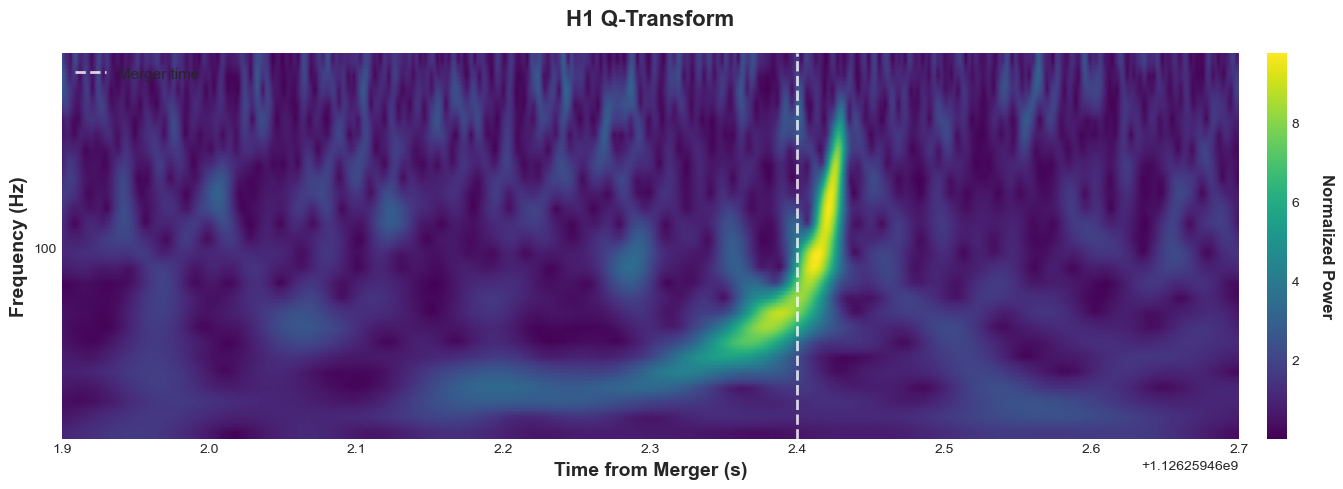

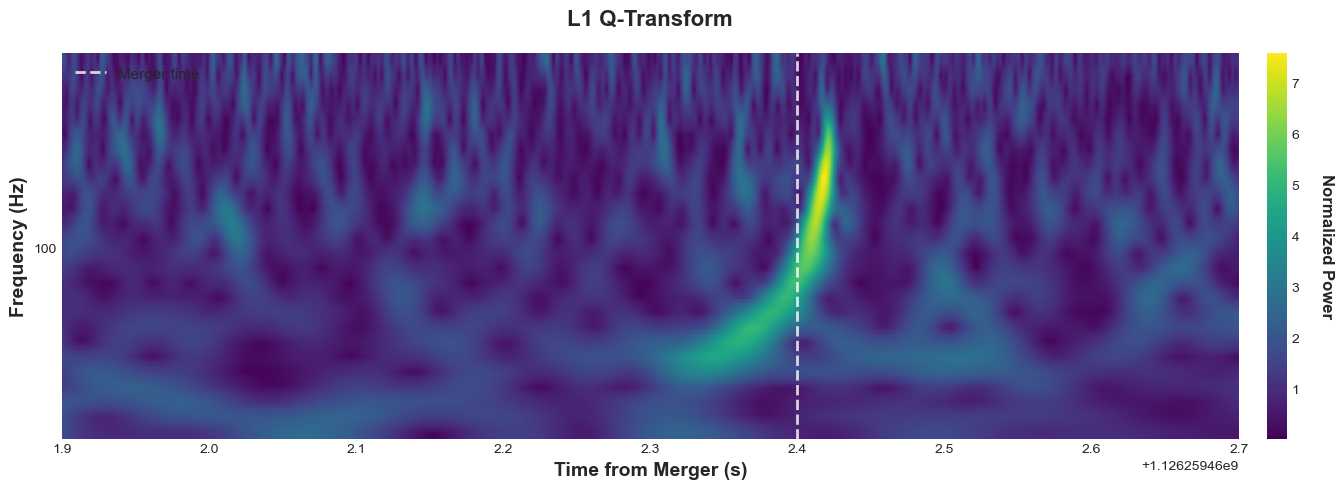

In [14]:
from matplotlib.colors import LogNorm
import matplotlib.ticker as ticker


for ifo in whitened:
    # We'll choose a tighter zoom here.
    zoom = whitened[ifo].time_slice(m.time - 5, m.time + 5)
                    
    ## The qtransform method returns a vector of the sample times, frequencies, and a 2-d vector of the 
    # power in each time-frequency bin. The free parameter is the choice of the Q-value. Larger Q-values
    # are generally more appropriate for viewing long duration features of the data and vice versa. 
                    
    # The options here:
    # (1) The time spacing for the output image (i.e. 1 ms in this case)
    # (2) The number of frequency bins in the output, logarithmically spaced
    # (3) The qrange to maximize over. We'll pick a constant at 8 here
    #     Typically higher values will be more appropriate for longer duration
    #     signals
    # (4) The frequency range to output
    
    times, freqs, power = zoom.qtransform(.001, logfsteps=100,
                                          qrange=(8, 8),
                                          frange=(20, 512))
    
    fig, ax = plt.subplots(figsize=(15, 5))
    
    # colormap
    im = ax.pcolormesh(times, freqs, power**0.5, 
                       cmap='viridis',  # or try 'magma', 'inferno', 'plasma'
                       shading='gouraud',  # smoother interpolation
                       rasterized=True)
    
    # vertical line at merger time
    ax.axvline(m.time, color='white', linestyle='--', 
               linewidth=2, alpha=0.8, label='Merger time')
    
    # axis limits
    ax.set_xlim(m.time - 0.5, m.time + 0.3)
    ax.set_ylim(20, 512)
    
    # labels
    ax.set_xlabel('Time from Merger (s)', fontsize=14, fontweight='bold')
    ax.set_ylabel('Frequency (Hz)', fontsize=14, fontweight='bold')
    ax.set_title(f'{ifo} Q-Transform', 
                 fontsize=16, fontweight='bold', pad=20)
    
    # Log scale for frequency
    ax.set_yscale('log')
    ax.yaxis.set_major_formatter(ticker.ScalarFormatter())
    ax.yaxis.set_minor_formatter(ticker.NullFormatter())
    
    # colorba
    cbar = plt.colorbar(im, ax=ax, pad=0.02)
    cbar.set_label('Normalized Power', fontsize=12, fontweight='bold', rotation=270, labelpad=25)
    cbar.ax.tick_params(labelsize=10)
    
    # merger time
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=8))
    
    # legend
    ax.legend(loc='upper left', fontsize=11, framealpha=0.9)
    
    # grid
    ax.grid(True, alpha=0.2, linestyle='--', linewidth=0.5, which='both')
    
    # plot
    plt.tight_layout()
    plt.show()